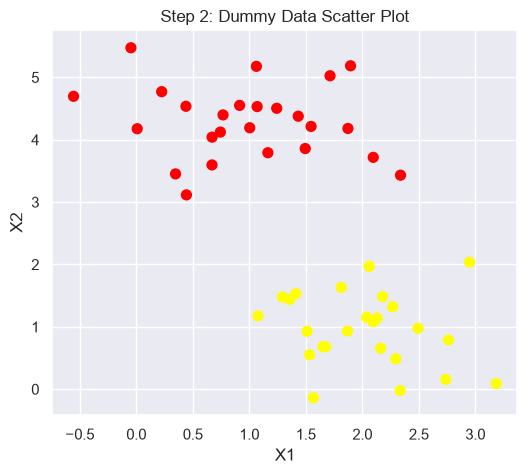

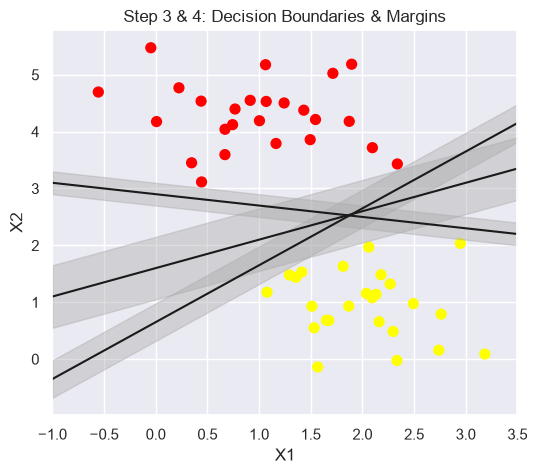

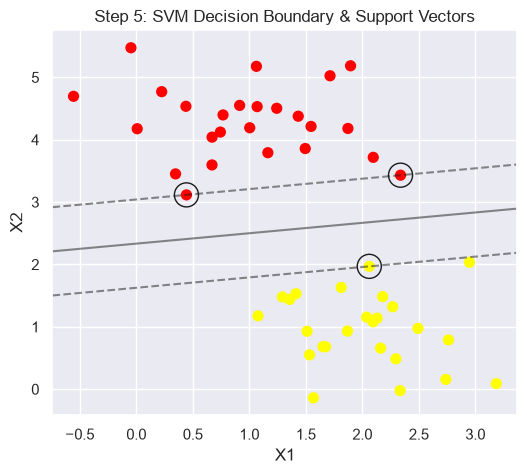

Support Vectors:
[[0.44359863 3.11530945]
 [2.33812285 3.43116792]
 [2.06156753 1.96918596]]


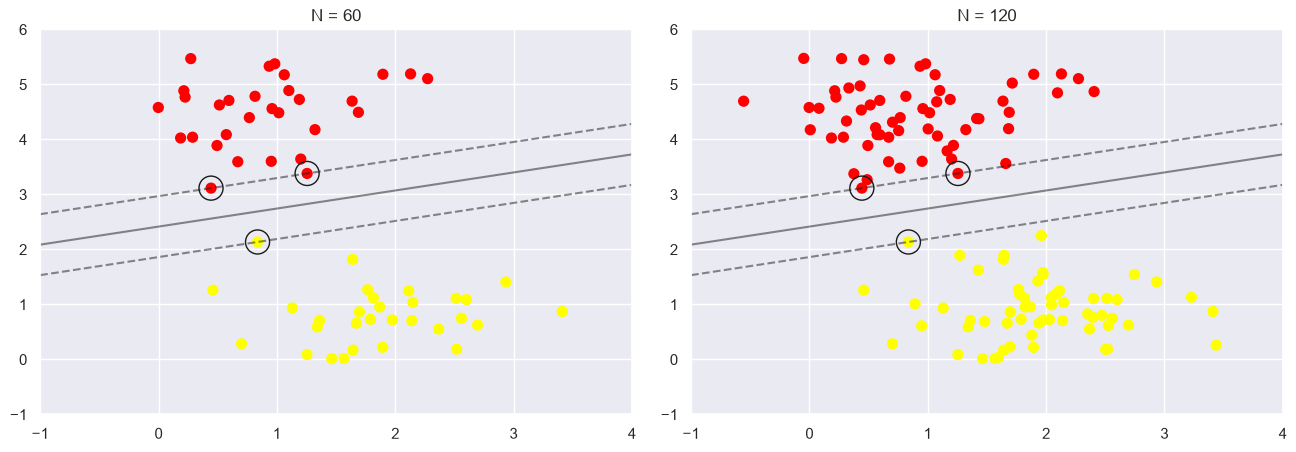

interactive(children=(Dropdown(description='N', options=(10, 60, 120, 200), value=10), Output()), _dom_classes…

<function __main__.plot_svm(N=10, ax=None)>

In [6]:
# ==============================================================================
# LAB 1: SVM Classification with Linear Dummy Data
# ==============================================================================

# --- Step 1: Import Libraries ---
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.datasets import make_blobs
from sklearn.svm import SVC
from ipywidgets import interact, fixed

# Set style matplotlib
sns.set_theme()


# --- Step 2: Create Dummy Data ---
X, y = make_blobs(n_samples=50, centers=2, random_state=0, cluster_std=0.60)

plt.figure(figsize=(6, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plt.title("Step 2: Dummy Data Scatter Plot")
plt.xlabel("X1")
plt.ylabel("X2")
plt.show()


# --- Step 3 & 4: Illustration of Decision Boundaries & Margins ---
xfit = np.linspace(-1, 3.5)

plt.figure(figsize=(6, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

# Plot beberapa opsi garis keputusan beserta marginnya
for m, b, d in [(1, 0.65, 0.33), (0.5, 1.6, 0.55), (-0.2, 2.9, 0.2)]:
    yfit = m * xfit + b
    plt.plot(xfit, yfit, '-k')
    plt.fill_between(xfit, yfit - d, yfit + d, edgecolor='none',
                     color='#AAAAAA', alpha=0.4)

plt.xlim(-1, 3.5)
plt.title("Step 3 & 4: Decision Boundaries & Margins")
plt.xlabel("X1")
plt.ylabel("X2")
plt.show()


# --- Step 5: Model Fitting & Decision Function Plotting ---

# Function untuk menampilkan visualisasi fit model SVM
def plot_svc_decision_function(model, ax=None, plot_support=True):
    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()
    
    # Buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)
    
    # Plot boundary dan margin
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])
    
    # Plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none', edgecolors='k')
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

# Fit model SVM dengan kernel linear
model = SVC(kernel='linear', C=1E10)
model.fit(X, y)

# Tampilkan hasil fitting
plt.figure(figsize=(6, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(model)
plt.title("Step 5: SVM Decision Boundary & Support Vectors")
plt.xlabel("X1")
plt.ylabel("X2")
plt.show()

# Menampilkan titik support vectors
print("Support Vectors:")
print(model.support_vectors_)


# --- Step 6: Effect of Sample Size (N = 60 vs N = 120) ---
def plot_svm(N=10, ax=None):
    X_samples, y_samples = make_blobs(n_samples=200, centers=2,
                                      random_state=0, cluster_std=0.60)
    X_samples = X_samples[:N]
    y_samples = y_samples[:N]
    
    model = SVC(kernel='linear', C=1E10)
    model.fit(X_samples, y_samples)
    
    ax = ax or plt.gca()
    ax.scatter(X_samples[:, 0], X_samples[:, 1], c=y_samples, s=50, cmap='autumn')
    ax.set_xlim(-1, 4)
    ax.set_ylim(-1, 6)
    plot_svc_decision_function(model, ax)

# Plot komparasi N=60 dan N=120
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)

for axi, N in zip(ax, [60, 120]):
    plot_svm(N, axi)
    axi.set_title('N = {0}'.format(N))

plt.show()


# --- Step 7: Interactive Plot (ipywidgets) ---
# Jalankan baris berikut di sel terpisah jika menggunakan Google Colab:
# !pip install ipywidgets

interact(plot_svm, N=[10, 60, 120, 200], ax=fixed(None))